# Aula Prática U3 A2: Redes Neurais Artificiais (XOR)

Fundamentos da Inteligência Artificial.

**Solução digital:** Visual Studio Code com Jupyter, no notebook pessoal do autor (Windows), versionado em repositório público no GitHub: https://github.com/ronichittoni/eng-soft-praticas/tree/main/U3_A2_redes_neurais. O roteiro indicava o Google Colab; este .ipynb abre nele sem conversão.

Aluno: Roni Chittoni.

## Decisão metodológica

O roteiro enuncia uma rede neural [2, 4, 1] para a função lógica XOR (objetivos, questões, checklist e seção de resultados), mas o código fornecido nas seis células é um sistema de lógica fuzzy para avaliação de qualidade de atendimento. Este notebook executa as duas partes:

* **Parte A**: código do roteiro reproduzido exatamente como entregue, para registro da execução literal (Ocorrência 1 do relatório).
* **Parte B**: rede neural [2, 4, 1] implementada do zero em NumPy, com sigmoid, retropropagação e descida do gradiente, que atende ao que o roteiro avalia.

## Evidências

O pipeline do VS Code (`Ctrl+Shift+B`) executa o notebook e extrai as saídas e figuras de cada célula para `evidencias/`, sem captura de tela.

| Evidência | Célula | Conteúdo | Uso no relatório |
|---|---|---|---|
| E01 | A0 | versões de Python, NumPy, Matplotlib e sistema | Materiais e Métodos |
| E02 | A5 | saída textual do teste do sistema fuzzy | Ocorrência 1 |
| E03 | A6 | os três gráficos fuzzy | Ocorrência 1 |
| E04 | B1 | dados XOR e gráfico da sigmoid com derivada | Questão 2 |
| E05 | B2 | arquitetura, contagem de parâmetros e pesos iniciais | Questões 1 e 6 |
| E06 | B3 | log de treinamento (época, MSE, acurácia) | Questão 3 |
| E07 | B4 | tabela saída da rede x esperado, MSE e acurácia finais | Questão 4, checklist |
| E08 | B5 | curvas de erro e de acurácia por época | Questão 3, checklist |
| E09 | B6 | superfície de decisão com limite em 0,5 | Questão 5, checklist |
| E10 | B7 | pesos antes e depois, ativações ocultas, mapa de calor de W1 | Questão 6 |
| E11 | B8 | um neurônio em AND, OR e XOR, com fronteiras lineares | Questões 1 e 7 |
| E12 | B9 | teste com dados sintéticos sobre a superfície | checklist |

Se alguma célula falhar ou a rede terminar abaixo de 100% em B4, o pipeline para antes do relatório: o estado vira Ocorrência, não se apaga.


## Parte A: código do roteiro (lógica fuzzy), reproduzido como entregue

In [1]:
# A0: registro do ambiente de execução
import sys, platform, numpy, matplotlib
print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Sistema:", platform.platform())

Python: 3.13.1
NumPy: 2.5.4
Matplotlib: 3.11.2
Sistema: Windows-11-10.0.26300-SP0


In [2]:
# Célula 1: Importar bibliotecas
import numpy as np
import matplotlib.pyplot as plt

# Configurar gráficos
plt.style.use('default')
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:
# Célula 2: Definir funções de pertinência para Tempo de Espera
def tempo_rapido(x):
    """Função de pertinência para tempo rápido (0-15 min)"""
    if x <= 10:
        return 1.0
    elif x <= 20:
        return (20 - x) / 10
    else:
        return 0.0

def tempo_medio(x):
    """Função de pertinência para tempo médio (10-30 min)"""
    if x <= 10:
        return 0.0
    elif x <= 20:
        return (x - 10) / 10
    elif x <= 30:
        return (30 - x) / 10
    else:
        return 0.0

def tempo_lento(x):
    """Função de pertinência para tempo lento (25-60 min)"""
    if x <= 25:
        return 0.0
    elif x <= 35:
        return (x - 25) / 10
    else:
        return 1.0

In [4]:
# Célula 3: Definir funções de pertinência para Cordialidade
def cordialidade_baixa(x):
    """Cordialidade baixa (0-4)"""
    if x <= 3:
        return 1.0
    elif x <= 5:
        return (5 - x) / 2
    else:
        return 0.0

def cordialidade_media(x):
    """Cordialidade média (3-7)"""
    if x <= 3:
        return 0.0
    elif x <= 5:
        return (x - 3) / 2
    elif x <= 7:
        return (7 - x) / 2
    else:
        return 0.0

def cordialidade_alta(x):
    """Cordialidade alta (6-10)"""
    if x <= 6:
        return 0.0
    elif x <= 8:
        return (x - 6) / 2
    else:
        return 1.0

In [5]:
# Célula 4: Definir regras do sistema fuzzy
def avaliar_atendimento(tempo, cordialidade):
    """
    Regras:
    1. Se tempo é rápido E cordialidade é alta → Qualidade EXCELENTE
    2. Se tempo é rápido E cordialidade é média → Qualidade BOA
    3. Se tempo é médio E cordialidade é alta → Qualidade BOA
    4. Se tempo é médio E cordialidade é média → Qualidade REGULAR
    5. Caso contrário → Qualidade RUIM
    """

    # Calcular graus de pertinência
    t_rapido = tempo_rapido(tempo)
    t_medio = tempo_medio(tempo)
    t_lento = tempo_lento(tempo)

    c_baixa = cordialidade_baixa(cordialidade)
    c_media = cordialidade_media(cordialidade)
    c_alta = cordialidade_alta(cordialidade)

    # Aplicar regras (usando operador MIN para E)
    excelente = min(t_rapido, c_alta)
    boa = max(min(t_rapido, c_media), min(t_medio, c_alta))
    regular = min(t_medio, c_media)
    ruim = max(min(t_lento, c_baixa), min(t_lento, c_media), min(t_lento, c_alta),
               min(t_rapido, c_baixa), min(t_medio, c_baixa))

    # Defuzzificação simples (valor numérico final)
    qualidade_final = (excelente * 9 + boa * 7 + regular * 5 + ruim * 2) / max(excelente + boa + regular + ruim, 0.001)

    return {
        'excelente': excelente,
        'boa': boa,
        'regular': regular,
        'ruim': ruim,
        'qualidade_final': qualidade_final
    }

In [6]:
# Célula 5: Testar o sistema
def testar_sistema():
    casos_teste = [
        {"tempo": 8, "cordialidade": 9, "descricao": "Atendimento rápido e muito cordial"},
        {"tempo": 15, "cordialidade": 6, "descricao": "Atendimento médio"},
        {"tempo": 35, "cordialidade": 3, "descricao": "Atendimento demorado e pouco cordial"},
        {"tempo": 12, "cordialidade": 8, "descricao": "Bom atendimento geral"}
    ]

    print("=== TESTE DO SISTEMA DE LÓGICA NEBULOSA ===\n")

    for i, caso in enumerate(casos_teste, 1):
        resultado = avaliar_atendimento(caso["tempo"], caso["cordialidade"])

        print(f"Caso {i}: {caso['descricao']}")
        print(f"  Tempo de espera: {caso['tempo']} minutos")
        print(f"  Cordialidade: {caso['cordialidade']}/10")
        print(f"  Graus de pertinência:")
        print(f"    Excelente: {resultado['excelente']:.2f}")
        print(f"    Boa: {resultado['boa']:.2f}")
        print(f"    Regular: {resultado['regular']:.2f}")
        print(f"    Ruim: {resultado['ruim']:.2f}")
        print(f"  Qualidade final: {resultado['qualidade_final']:.2f}/10\n")

testar_sistema()

=== TESTE DO SISTEMA DE LÓGICA NEBULOSA ===

Caso 1: Atendimento rápido e muito cordial
  Tempo de espera: 8 minutos
  Cordialidade: 9/10
  Graus de pertinência:
    Excelente: 1.00
    Boa: 0.00
    Regular: 0.00
    Ruim: 0.00
  Qualidade final: 9.00/10

Caso 2: Atendimento médio
  Tempo de espera: 15 minutos
  Cordialidade: 6/10
  Graus de pertinência:
    Excelente: 0.00
    Boa: 0.50
    Regular: 0.50
    Ruim: 0.00
  Qualidade final: 6.00/10

Caso 3: Atendimento demorado e pouco cordial
  Tempo de espera: 35 minutos
  Cordialidade: 3/10
  Graus de pertinência:
    Excelente: 0.00
    Boa: 0.00
    Regular: 0.00
    Ruim: 1.00
  Qualidade final: 2.00/10

Caso 4: Bom atendimento geral
  Tempo de espera: 12 minutos
  Cordialidade: 8/10
  Graus de pertinência:
    Excelente: 0.80
    Boa: 0.20
    Regular: 0.00
    Ruim: 0.00
  Qualidade final: 8.60/10



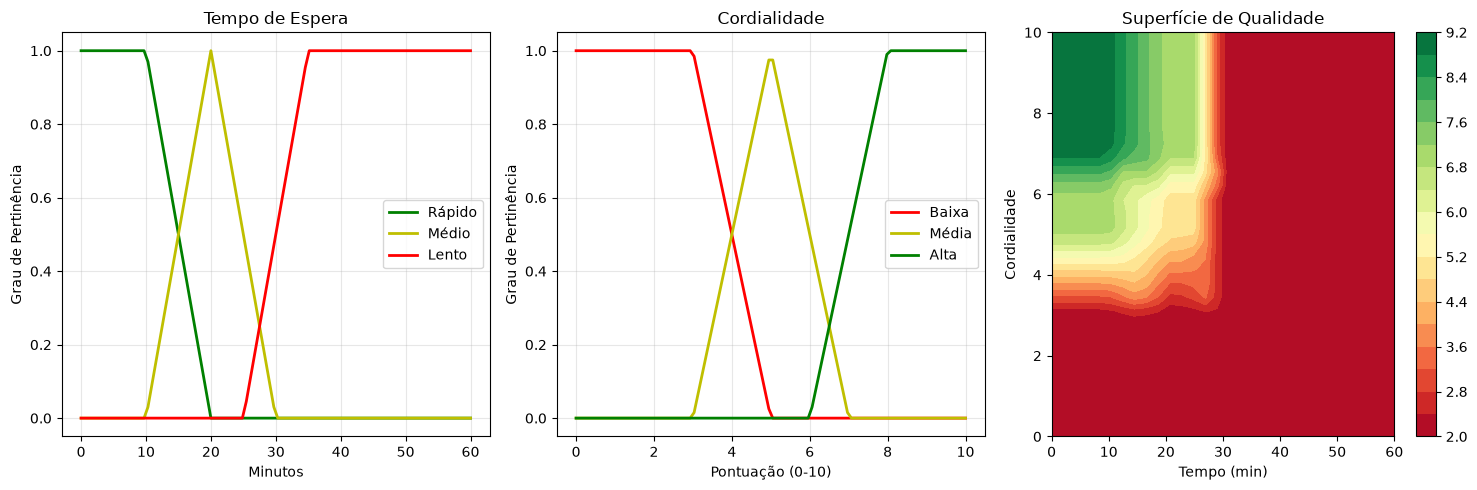

In [7]:
# Célula 6: Visualizar as funções de pertinência
def plotar_funcoes_pertinencia():
    # Tempo
    tempo_range = np.linspace(0, 60, 100)
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.plot(tempo_range, [tempo_rapido(t) for t in tempo_range], 'g-', label='Rápido', linewidth=2)
    plt.plot(tempo_range, [tempo_medio(t) for t in tempo_range], 'y-', label='Médio', linewidth=2)
    plt.plot(tempo_range, [tempo_lento(t) for t in tempo_range], 'r-', label='Lento', linewidth=2)
    plt.title('Tempo de Espera')
    plt.xlabel('Minutos')
    plt.ylabel('Grau de Pertinência')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # Cordialidade
    cord_range = np.linspace(0, 10, 100)
    plt.subplot(1, 3, 2)
    plt.plot(cord_range, [cordialidade_baixa(c) for c in cord_range], 'r-', label='Baixa', linewidth=2)
    plt.plot(cord_range, [cordialidade_media(c) for c in cord_range], 'y-', label='Média', linewidth=2)
    plt.plot(cord_range, [cordialidade_alta(c) for c in cord_range], 'g-', label='Alta', linewidth=2)
    plt.title('Cordialidade')
    plt.xlabel('Pontuação (0-10)')
    plt.ylabel('Grau de Pertinência')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # Superfície de qualidade
    plt.subplot(1, 3, 3)
    T, C = np.meshgrid(np.linspace(0, 60, 30), np.linspace(0, 10, 30))
    Z = np.zeros_like(T)

    for i in range(T.shape[0]):
        for j in range(T.shape[1]):
            resultado = avaliar_atendimento(T[i,j], C[i,j])
            Z[i,j] = resultado['qualidade_final']

    contour = plt.contourf(T, C, Z, levels=20, cmap='RdYlGn')
    plt.colorbar(contour)
    plt.title('Superfície de Qualidade')
    plt.xlabel('Tempo (min)')
    plt.ylabel('Cordialidade')

    plt.tight_layout()
    plt.show()

plotar_funcoes_pertinencia()

## Parte B: rede neural [2, 4, 1] para XOR, implementada do zero

Arquitetura: 2 neurônios de entrada (x1, x2), 4 neurônios na camada oculta, 1 neurônio de saída. Ativação sigmoid em todas as camadas. Treinamento por retropropagação do erro com descida do gradiente (batch, as quatro amostras por época).

Entradas X (x1, x2):
 [[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
Saídas esperadas y (XOR): [0. 1. 1. 0.]


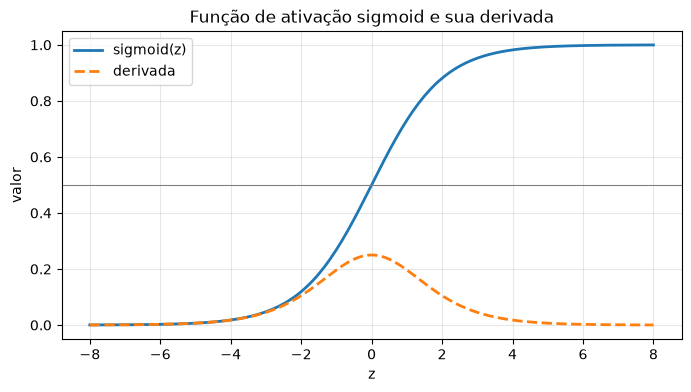

In [8]:
# B1: dados do problema XOR e função de ativação sigmoid
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_derivada(a):
    """Derivada da sigmoid expressa pela própria ativação a = sigmoid(z): a * (1 - a)."""
    return a * (1.0 - a)

print("Entradas X (x1, x2):\n", X)
print("Saídas esperadas y (XOR):", y.ravel())

z = np.linspace(-8, 8, 200)
plt.figure(figsize=(8, 4))
plt.plot(z, sigmoid(z), label='sigmoid(z)', linewidth=2)
plt.plot(z, sigmoid_derivada(sigmoid(z)), '--', label='derivada', linewidth=2)
plt.axhline(0.5, color='gray', linewidth=0.8)
plt.title('Função de ativação sigmoid e sua derivada')
plt.xlabel('z'); plt.ylabel('valor'); plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

In [9]:
# B2: arquitetura [2, 4, 1] e inicialização dos pesos
np.random.seed(42)
n_entrada, n_oculta, n_saida = 2, 4, 1

W1 = np.random.uniform(-1, 1, size=(n_entrada, n_oculta))   # entrada -> oculta
b1 = np.zeros((1, n_oculta))
W2 = np.random.uniform(-1, 1, size=(n_oculta, n_saida))     # oculta -> saída
b2 = np.zeros((1, n_saida))

W1_inicial, b1_inicial = W1.copy(), b1.copy()
W2_inicial, b2_inicial = W2.copy(), b2.copy()

total = W1.size + b1.size + W2.size + b2.size
print(f"Arquitetura: {n_entrada} neurônios de entrada, {n_oculta} ocultos, {n_saida} de saída")
print(f"Parâmetros treináveis: {total} (W1 {W1.size} + b1 {b1.size} + W2 {W2.size} + b2 {b2.size})")
np.set_printoptions(precision=4, suppress=True)
print("\nW1 inicial (2x4):\n", W1)
print("b1 inicial (1x4):\n", b1)
print("W2 inicial (4x1):\n", W2)
print("b2 inicial (1x1):\n", b2)

Arquitetura: 2 neurônios de entrada, 4 ocultos, 1 de saída
Parâmetros treináveis: 17 (W1 8 + b1 4 + W2 4 + b2 1)

W1 inicial (2x4):
 [[-0.2509  0.9014  0.464   0.1973]
 [-0.688  -0.688  -0.8838  0.7324]]
b1 inicial (1x4):
 [[0. 0. 0. 0.]]
W2 inicial (4x1):
 [[ 0.2022]
 [ 0.4161]
 [-0.9588]
 [ 0.9398]]
b2 inicial (1x1):
 [[0.]]


In [10]:
# B3: propagação frontal, retropropagação e treinamento por descida do gradiente
def propagacao_frontal(X, W1, b1, W2, b2):
    z1 = X @ W1 + b1
    a1 = sigmoid(z1)          # ativações da camada oculta
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)          # saída da rede
    return a1, a2

taxa_aprendizado = 0.5
epocas = 10000
historico_erro = []
historico_acuracia = []

for epoca in range(1, epocas + 1):
    # 1. Propagação frontal
    a1, a2 = propagacao_frontal(X, W1, b1, W2, b2)

    # 2. Erro quadrático médio e acurácia da época
    erro = y - a2
    mse = np.mean(erro ** 2)
    acuracia = np.mean((a2 >= 0.5) == (y == 1))
    historico_erro.append(mse)
    historico_acuracia.append(acuracia)

    # 3. Retropropagação: gradiente local de cada camada
    delta2 = erro * sigmoid_derivada(a2)                 # camada de saída
    delta1 = (delta2 @ W2.T) * sigmoid_derivada(a1)      # camada oculta

    # 4. Atualização dos pesos e bias (descida do gradiente)
    W2 += taxa_aprendizado * (a1.T @ delta2)
    b2 += taxa_aprendizado * delta2.sum(axis=0, keepdims=True)
    W1 += taxa_aprendizado * (X.T @ delta1)
    b1 += taxa_aprendizado * delta1.sum(axis=0, keepdims=True)

    if epoca == 1 or epoca % 1000 == 0:
        print(f"Época {epoca:6d} | MSE = {mse:.6f} | acurácia = {acuracia * 100:5.1f}%")

Época      1 | MSE = 0.262916 | acurácia =  50.0%


Época   1000 | MSE = 0.005865 | acurácia = 100.0%
Época   2000 | MSE = 0.001788 | acurácia = 100.0%
Época   3000 | MSE = 0.001019 | acurácia = 100.0%
Época   4000 | MSE = 0.000705 | acurácia = 100.0%
Época   5000 | MSE = 0.000536 | acurácia = 100.0%
Época   6000 | MSE = 0.000431 | acurácia = 100.0%
Época   7000 | MSE = 0.000360 | acurácia = 100.0%
Época   8000 | MSE = 0.000309 | acurácia = 100.0%


Época   9000 | MSE = 0.000270 | acurácia = 100.0%


Época  10000 | MSE = 0.000239 | acurácia = 100.0%


In [11]:
# B4: resultado final da rede treinada
_, saida = propagacao_frontal(X, W1, b1, W2, b2)
predicao = (saida >= 0.5).astype(int)
acuracia_final = np.mean(predicao == y.astype(int)) * 100

print("Entrada | Esperado | Saída da rede | Predição | Correto")
for xi, yi, si, pi in zip(X, y.ravel(), saida.ravel(), predicao.ravel()):
    print(f" {xi.astype(int)}  |    {int(yi)}     |    {si:.4f}     |    {pi}     | {'sim' if pi == yi else 'não'}")
print(f"\nMSE final: {historico_erro[-1]:.6f}")
print(f"Acurácia final: {acuracia_final:.0f}%")

Entrada | Esperado | Saída da rede | Predição | Correto
 [0 0]  |    0     |    0.0095     |    0     | sim
 [0 1]  |    1     |    0.9839     |    1     | sim
 [1 0]  |    1     |    0.9849     |    1     | sim
 [1 1]  |    0     |    0.0195     |    0     | sim

MSE final: 0.000239
Acurácia final: 100%


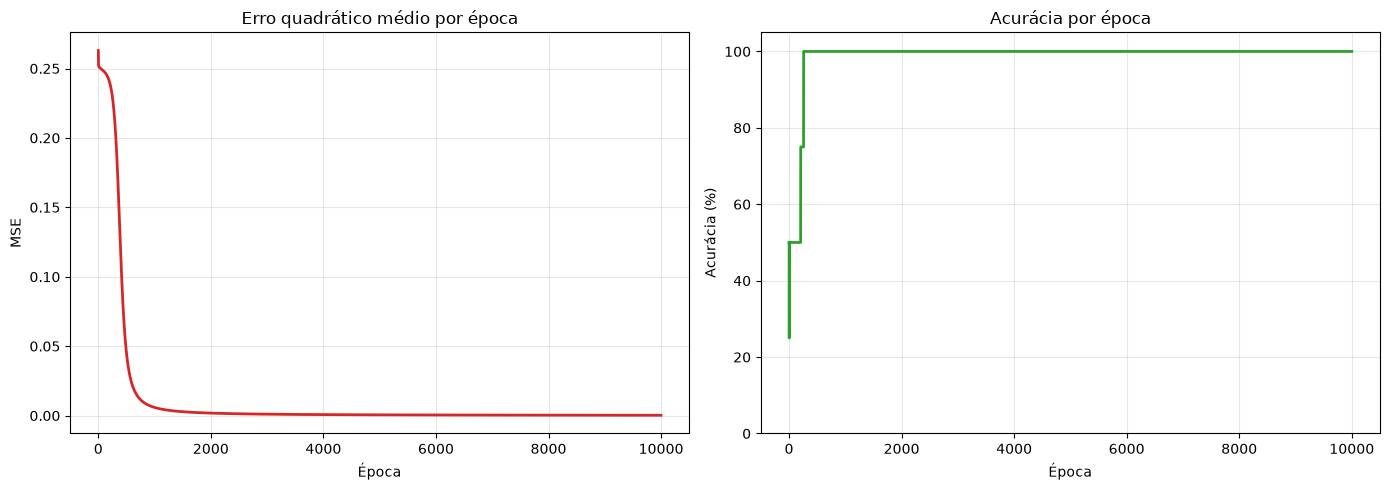

In [12]:
# B5: evolução do erro e da acurácia ao longo das épocas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(historico_erro, color='tab:red', linewidth=2)
ax1.set_title('Erro quadrático médio por época')
ax1.set_xlabel('Época'); ax1.set_ylabel('MSE'); ax1.grid(True, alpha=0.3)
ax2.plot(np.array(historico_acuracia) * 100, color='tab:green', linewidth=2)
ax2.set_title('Acurácia por época')
ax2.set_xlabel('Época'); ax2.set_ylabel('Acurácia (%)'); ax2.set_ylim(0, 105); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

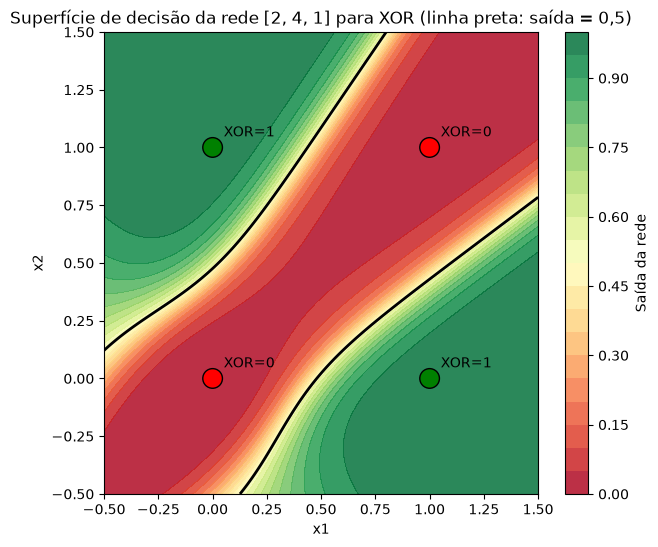

In [13]:
# B6: superfície de decisão aprendida
gx, gy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grade = np.c_[gx.ravel(), gy.ravel()]
_, z_grade = propagacao_frontal(grade, W1, b1, W2, b2)
Z = z_grade.reshape(gx.shape)

plt.figure(figsize=(7, 6))
cf = plt.contourf(gx, gy, Z, levels=20, cmap='RdYlGn', alpha=0.85)
plt.colorbar(cf, label='Saída da rede')
plt.contour(gx, gy, Z, levels=[0.5], colors='black', linewidths=2)   # limite de decisão
cores = ['red' if v == 0 else 'green' for v in y.ravel()]
plt.scatter(X[:, 0], X[:, 1], c=cores, s=200, edgecolors='black', zorder=5)
for xi, yi in zip(X, y.ravel()):
    plt.annotate(f'XOR={int(yi)}', (xi[0], xi[1]), textcoords='offset points', xytext=(8, 8))
plt.title('Superfície de decisão da rede [2, 4, 1] para XOR (linha preta: saída = 0,5)')
plt.xlabel('x1'); plt.ylabel('x2'); plt.show()

W1 inicial (entrada -> oculta):
 [[-0.2509  0.9014  0.464   0.1973]
 [-0.688  -0.688  -0.8838  0.7324]] 
W1 final:
 [[-0.402   4.6078  6.3709  3.8283]
 [-1.203  -6.2624 -4.7744  3.8466]]

b1 inicial: [0. 0. 0. 0.] 
b1 final:   [ 0.4821 -2.0577  2.0946 -0.5984]

W2 inicial (oculta -> saída): [ 0.2022  0.4161 -0.9588  0.9398] 
W2 final:   [ 1.5059  8.9252 -9.086   4.4415]

b2 inicial: [0.] 
b2 final:   [-0.0752]

Ativações da camada oculta (h1 h2 h3 h4) e saída para cada entrada:
  x = [0 0] -> h = [0.6183 0.1133 0.8904 0.3547] -> saída = 0.0095
  x = [0 1] -> h = [0.3272 0.0002 0.0642 0.9626] -> saída = 0.9839
  x = [1 0] -> h = [0.52   0.9276 0.9998 0.9619] -> saída = 0.9849
  x = [1 1] -> h = [0.2455 0.0238 0.9757 0.9992] -> saída = 0.0195


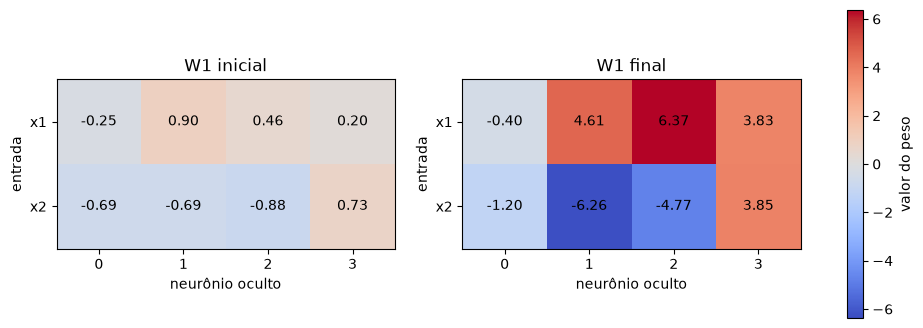

In [14]:
# B7: análise dos pesos e das ativações da camada oculta
print("W1 inicial (entrada -> oculta):\n", W1_inicial, "\nW1 final:\n", W1)
print("\nb1 inicial:", b1_inicial.ravel(), "\nb1 final:  ", b1.ravel())
print("\nW2 inicial (oculta -> saída):", W2_inicial.ravel(), "\nW2 final:  ", W2.ravel())
print("\nb2 inicial:", b2_inicial.ravel(), "\nb2 final:  ", b2.ravel())

a1_final, a2_final = propagacao_frontal(X, W1, b1, W2, b2)
print("\nAtivações da camada oculta (h1 h2 h3 h4) e saída para cada entrada:")
for xi, hi, oi in zip(X, a1_final, a2_final.ravel()):
    print(f"  x = {xi.astype(int)} -> h = {hi} -> saída = {oi:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
escala = max(np.abs(W1_inicial).max(), np.abs(W1).max())
for ax, M, titulo in zip(axes, [W1_inicial, W1], ['W1 inicial', 'W1 final']):
    im = ax.imshow(M, cmap='coolwarm', vmin=-escala, vmax=escala)
    ax.set_title(titulo); ax.set_xlabel('neurônio oculto'); ax.set_ylabel('entrada')
    ax.set_xticks(range(n_oculta)); ax.set_yticks(range(n_entrada))
    ax.set_yticklabels(['x1', 'x2'])
    for (i, j), v in np.ndenumerate(M):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center')
fig.colorbar(im, ax=axes.ravel().tolist(), label='valor do peso')
plt.show()

AND: saídas = [0.    0.023 0.023 0.972] | acurácia = 100%


OR: saídas = [0.023 0.985 0.985 1.   ] | acurácia = 100%
XOR: saídas = [0.5 0.5 0.5 0.5] | acurácia = 50%


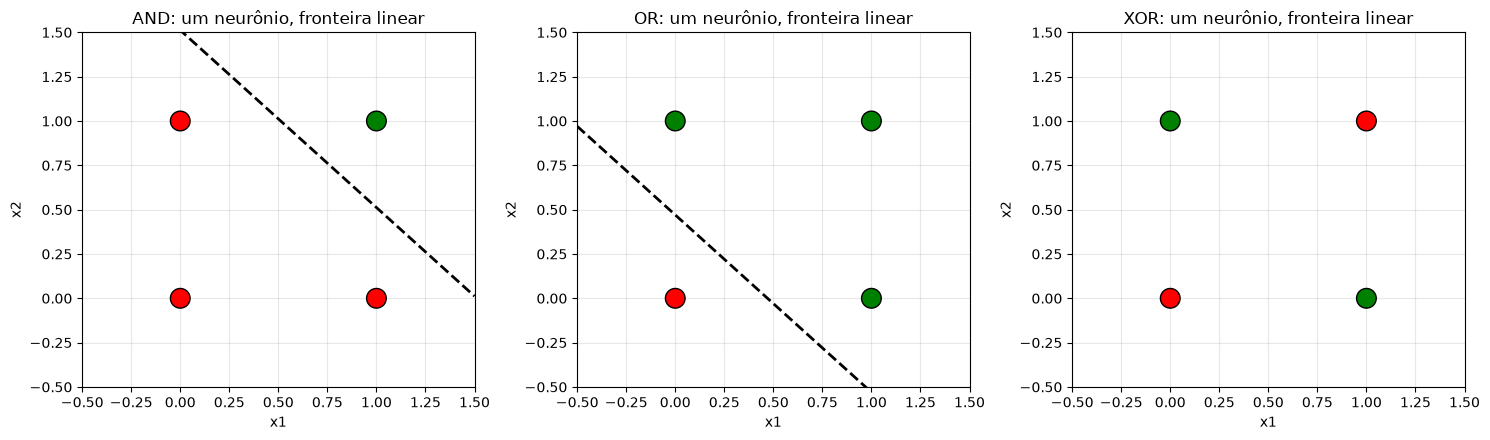

In [15]:
# B8: contraprova, um único neurônio (sem camada oculta) em AND, OR e XOR
def treinar_neuronio_unico(X, alvo, taxa=0.5, epocas=10000, seed=42):
    rng = np.random.default_rng(seed)
    w = rng.uniform(-1, 1, size=(2, 1))
    b = np.zeros((1, 1))
    for _ in range(epocas):
        a = sigmoid(X @ w + b)
        delta = (alvo - a) * sigmoid_derivada(a)
        w += taxa * (X.T @ delta)
        b += taxa * delta.sum(axis=0, keepdims=True)
    a = sigmoid(X @ w + b)
    acc = np.mean((a >= 0.5) == (alvo == 1)) * 100
    return w, b, a, acc

problemas = {
    'AND': np.array([[0], [0], [0], [1]], dtype=float),
    'OR':  np.array([[0], [1], [1], [1]], dtype=float),
    'XOR': y,
}
resultados_1n = {}
for nome, alvo in problemas.items():
    w, b, a, acc = treinar_neuronio_unico(X, alvo)
    resultados_1n[nome] = (w, b)
    print(f"{nome}: saídas = {np.round(a.ravel(), 3)} | acurácia = {acc:.0f}%")

# fronteira linear de cada neurônio: w1*x1 + w2*x2 + b = 0
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
xs = np.linspace(-0.5, 1.5, 100)
for ax, (nome, alvo) in zip(axes, problemas.items()):
    w, b = resultados_1n[nome]
    cores = ['red' if v == 0 else 'green' for v in alvo.ravel()]
    ax.scatter(X[:, 0], X[:, 1], c=cores, s=200, edgecolors='black', zorder=5)
    if abs(w[1, 0]) > 1e-9:
        ax.plot(xs, -(w[0, 0] * xs + b[0, 0]) / w[1, 0], 'k--', linewidth=2, label='fronteira linear')
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
    ax.set_title(f'{nome}: um neurônio, fronteira linear')
    ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Amostras sintéticas: 200 | erros: 1 | acurácia: 99.5%


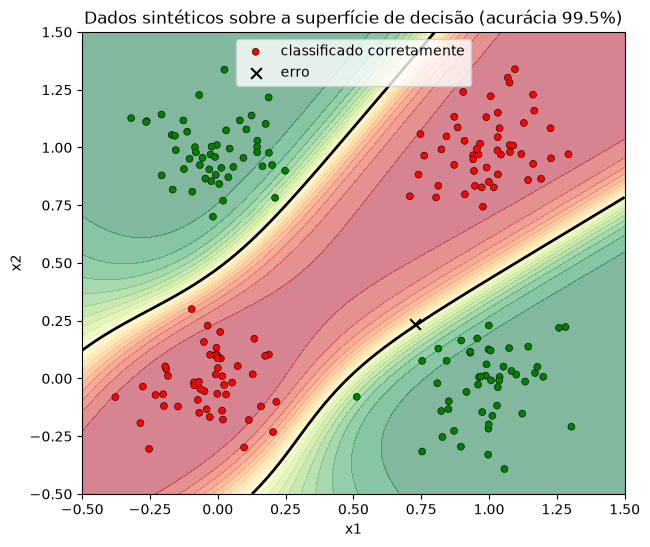

In [16]:
# B9: teste com dados sintéticos (ruído gaussiano em torno das quatro entradas)
rng = np.random.default_rng(7)
n_por_ponto = 50
X_sint = np.vstack([xi + rng.normal(0, 0.15, size=(n_por_ponto, 2)) for xi in X])
y_sint = np.vstack([np.full((n_por_ponto, 1), yi) for yi in y.ravel()])

_, saida_sint = propagacao_frontal(X_sint, W1, b1, W2, b2)
pred_sint = (saida_sint >= 0.5).astype(float)
acc_sint = np.mean(pred_sint == y_sint) * 100
erros = int(np.sum(pred_sint != y_sint))
print(f"Amostras sintéticas: {len(X_sint)} | erros: {erros} | acurácia: {acc_sint:.1f}%")

acertou = (pred_sint == y_sint).ravel()
plt.figure(figsize=(7, 6))
plt.contourf(gx, gy, Z, levels=20, cmap='RdYlGn', alpha=0.5)
plt.contour(gx, gy, Z, levels=[0.5], colors='black', linewidths=2)
plt.scatter(X_sint[acertou, 0], X_sint[acertou, 1],
            c=['green' if v == 1 else 'red' for v in y_sint[acertou].ravel()],
            s=25, edgecolors='black', linewidths=0.4, label='classificado corretamente')
if (~acertou).any():
    plt.scatter(X_sint[~acertou, 0], X_sint[~acertou, 1], marker='x', c='black', s=60, label='erro')
plt.title(f'Dados sintéticos sobre a superfície de decisão (acurácia {acc_sint:.1f}%)')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend(loc='upper center'); plt.show()

## Entrega

Checklist do roteiro coberto por B1 a B9 (rede implementada, XOR resolvido, gráfico de erro, superfície de decisão, teste sintético, acurácia). O relatório (.docx e PDF) é gerado pelo pipeline em `saida/`, e o notebook executado fica versionado no repositório.